In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Setting display options for pandas and matplotlib
pd.set_option('display.max_columns', 30)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Loading the dataset from saved CSV file
data_path = os.path.join('..', 'data', 'owid-energy-data.csv')
df = pd.read_csv(data_path)

# Inspecting the dataset
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Year Range:    {df["year"].min()} to {df["year"].max()}')
print(f'Total Entities (Countries & Aggregates): {df["country"].nunique()}')

# Preview basic metadata of the dataset
print('\nDataset Info:')
df.info()  
display(df[['country', 'year', 'iso_code', 'population', 'gdp']].head(5))

Dataset Shape: 23377 rows, 130 columns
Year Range:    1900 to 2025
Total Entities (Countries & Aggregates): 314

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 23377 entries, 0 to 23376
Columns: 130 entries, country to wind_share_energy
dtypes: float64(127), int64(1), str(2)
memory usage: 23.2 MB


,country,year,iso_code,population,gdp
0,ASEAN (Ember),2000,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN


In [2]:
# Separating sovereign countries from regional aggregates based on the presence of ISO codes
# Sovereign countries have an official 3-letter ISO code (e.g., 'DEU', 'USA', 'CMR')
sovereign_df = df[df['iso_code'].notna()].copy()
aggregates_df = df[df['iso_code'].isna()].copy()

print(f"Total Unique Sovereign Countries: {sovereign_df['country'].nunique()}")
print(f"Total Unique Regional Aggregates: {aggregates_df['country'].nunique()}")

# Previewing regional aggregates (entities without ISO codes)
print("\nSample Aggregate Entities (No ISO Code):")
print(aggregates_df['country'].drop_duplicates().head(8).tolist())

# Identifying the 8 core fuel consumption columns in the dataset
energy_source_cols = [
    'coal_consumption',
    'oil_consumption',
    'gas_consumption',
    'nuclear_consumption',
    'hydro_consumption',
    'solar_consumption',
    'wind_consumption',
    'other_renewable_consumption'
]

# Checking for the presence of the 8 core fuel consumption columns in the dataset
missing_cols = [col for col in energy_source_cols if col not in df.columns]
print(f"\nMissing Target Columns: {missing_cols if missing_cols else 'None - All 8 core fuel columns exist!'}")

# Filtering the dataset for Germany (DEU) from 2015 onwards and displaying relevant columns
deu_recent = sovereign_df[(sovereign_df['iso_code'] == 'DEU') & (sovereign_df['year'] >= 2015)]
display(deu_recent[['year', 'country', 'primary_energy_consumption'] + energy_source_cols].head())

Total Unique Sovereign Countries: 220
Total Unique Regional Aggregates: 94

Sample Aggregate Entities (No ISO Code):
['ASEAN (Ember)', 'Africa', 'Africa (EI)', 'Africa (EIA)', 'Africa (Ember)', 'Africa (Shift)', 'Asia', 'Asia (Ember)']

Missing Target Columns: None - All 8 core fuel columns exist!


,year,country,primary_energy_consumption,coal_consumption,oil_consumption,gas_consumption,nuclear_consumption,hydro_consumption,solar_consumption,wind_consumption,other_renewable_consumption
8272,2015,Germany,3780.860,915.056,1296.542,769.536,232.370,48.043,96.395,204.111,157.686
8273,2016,Germany,3841.451,889.935,1321.879,848.847,212.649,51.623,94.362,200.814,159.698
8274,2017,Germany,3949.556,835.930,1408.928,877.385,190.811,50.375,96.903,264.232,159.626
8275,2018,Germany,3845.414,806.690,1336.970,858.507,189.067,44.012,110.249,273.510,159.286
8276,2019,Germany,3753.704,624.218,1351.028,892.830,185.820,48.839,111.933,311.619,157.261


In [3]:
# Filtering the dataset for sovereign countries and the years 1990-2024
analysis_df = sovereign_df[(sovereign_df['year'] >= 1990) & (sovereign_df['year'] <= 2024)].copy()

# Sorting the DataFrame by 'iso_code'(country) and 'year' for consistent processing (preserving time-series order)
analysis_df = analysis_df.sort_values(by=['iso_code', 'year']).reset_index(drop=True)

# 1. Rule 1: Filling missing values with zero for technologies that are not widely deployed (solar, wind, nuclear, other renewables)
tech_zero_cols = [
    'solar_consumption',
    'wind_consumption',
    'nuclear_consumption',
    'other_renewable_consumption'
]
analysis_df[tech_zero_cols] = analysis_df[tech_zero_cols].fillna(0.0)

# 1. Rule 2: Applying segmented Linear Interpolation (Internal reporting gaps only, max 2 consecutive years)
continuous_cols = [
    'coal_consumption',
    'oil_consumption',
    'gas_consumption',
    'hydro_consumption'
]
analysis_df[continuous_cols] = analysis_df.groupby('iso_code')[continuous_cols].transform(
    lambda group: group.interpolate(method='linear', limit=2, limit_area='inside')
)

# 2. Creating macro-categories (in TWh)
analysis_df['fossil_consumption'] = (
    analysis_df['coal_consumption'] + 
    analysis_df['oil_consumption'] + 
    analysis_df['gas_consumption']
)

analysis_df['renewables_consumption'] = (
    analysis_df['hydro_consumption'] + 
    analysis_df['solar_consumption'] + 
    analysis_df['wind_consumption'] + 
    analysis_df['other_renewable_consumption']
)

# 3. Creating a new column for total accounted primary energy consumption (TWh)
analysis_df['total_accounted_twh'] = (
    analysis_df['fossil_consumption'] + 
    analysis_df['nuclear_consumption'] + 
    analysis_df['renewables_consumption']
)

# 4. Creating share columns for fossil, nuclear, and renewables (as percentages of total accounted consumption)
analysis_df['fossil_share_pct'] = np.where(
    analysis_df['total_accounted_twh'] > 0,
    (analysis_df['fossil_consumption'] / analysis_df['total_accounted_twh']) * 100,
    np.nan
)

analysis_df['nuclear_share_pct'] = np.where(
    analysis_df['total_accounted_twh'] > 0,
    (analysis_df['nuclear_consumption'] / analysis_df['total_accounted_twh']) * 100,
    np.nan
)

analysis_df['renewables_share_pct'] = np.where(
    analysis_df['total_accounted_twh'] > 0,
    (analysis_df['renewables_consumption'] / analysis_df['total_accounted_twh']) * 100,
    np.nan
)

# 5. Previewing the energy transition trajectory for Germany (DEU) across selected years
summary_cols = [
    'year',
    'fossil_share_pct',
    'nuclear_share_pct',
    'renewables_share_pct',
    'total_accounted_twh'
]
deu_trajectory = analysis_df[
    (analysis_df['iso_code'] == 'DEU') & 
    (analysis_df['year'].isin([1990, 2000, 2010, 2020, 2023]))
]

display(deu_trajectory[summary_cols].round(2))

,year,fossil_share_pct,nuclear_share_pct,renewables_share_pct,total_accounted_twh
1778,1990,88.60,10.13,1.26,4180.32
1788,2000,85.45,11.87,2.68,3969.09
1798,2010,82.65,9.65,7.70,3792.76
1808,2020,76.25,4.65,19.10,3421.66
1811,2023,76.72,0.57,22.72,3103.49


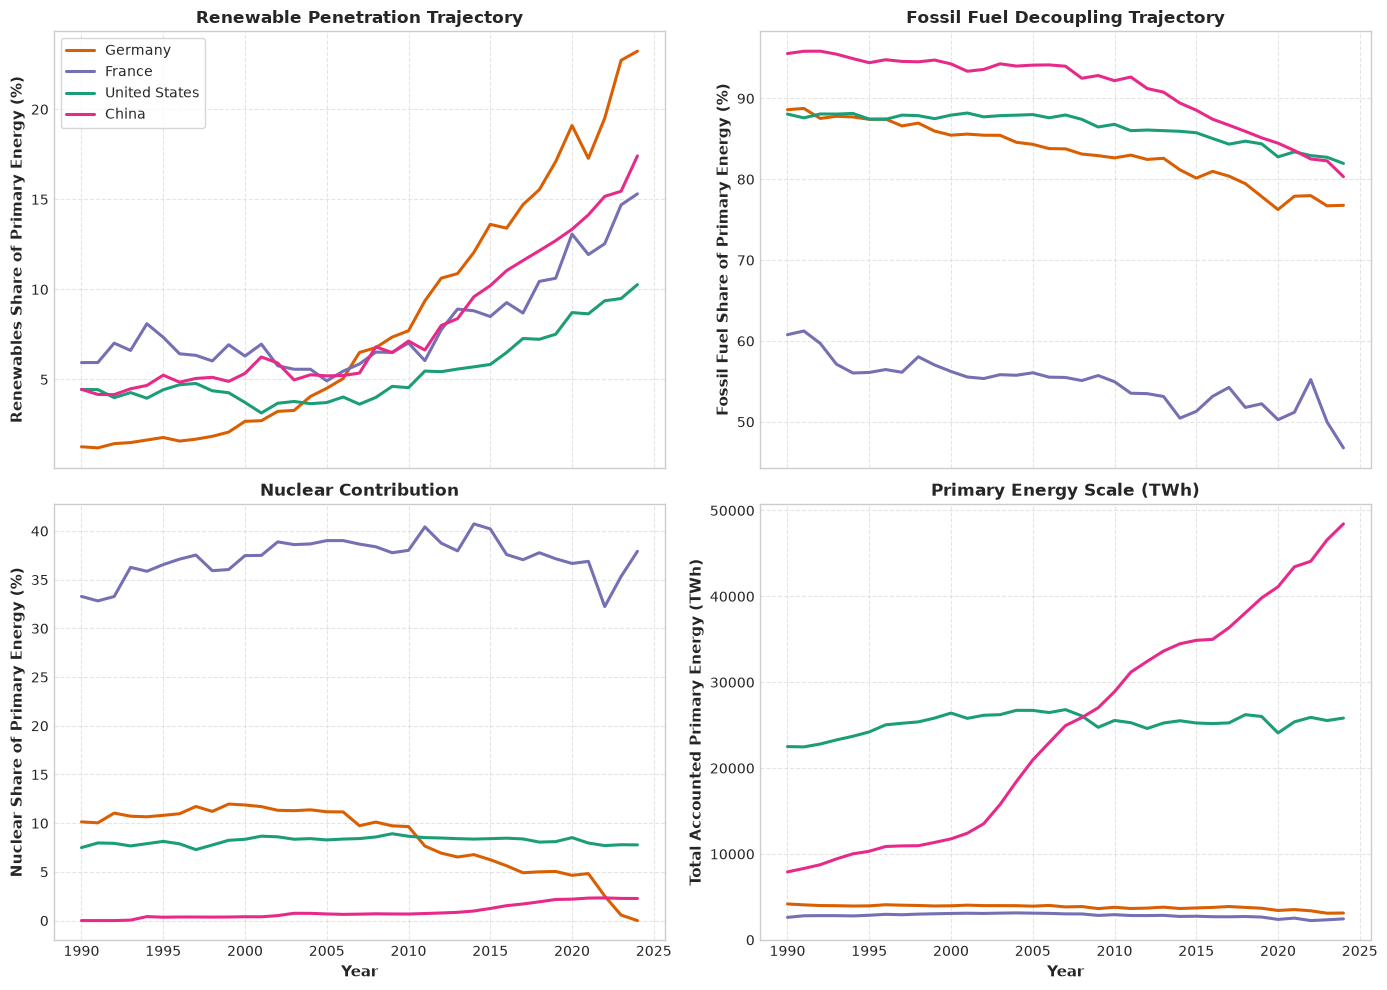

Figure saved to: ../figures/multi_country_transition_comparison.png


In [4]:
# 6. Visualizing the energy transition trajectories for Germany (DEU), France (FRA), United States (USA), and China (CHN)
focus_isos = ['DEU', 'FRA', 'USA', 'CHN']
cohort_df = analysis_df[analysis_df['iso_code'].isin(focus_isos)].copy()

# Setting up a 2x2 grid of subplots for the four metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

metrics = [
    ('renewables_share_pct', 'Renewables Share of Primary Energy (%)', axes[0, 0]),
    ('fossil_share_pct', 'Fossil Fuel Share of Primary Energy (%)', axes[0, 1]),
    ('nuclear_share_pct', 'Nuclear Share of Primary Energy (%)', axes[1, 0]),
    ('total_accounted_twh', 'Total Accounted Primary Energy (TWh)', axes[1, 1])
]

palette = {'DEU': '#d95f02', 'FRA': '#7570b3', 'USA': '#1b9e77', 'CHN': '#e7298a'}
labels = {'DEU': 'Germany', 'FRA': 'France', 'USA': 'United States', 'CHN': 'China'}

for col_name, y_label, ax in metrics:
    for iso in focus_isos:
        country_subset = cohort_df[cohort_df['iso_code'] == iso]
        ax.plot(
            country_subset['year'],
            country_subset[col_name],
            label=labels[iso],
            color=palette[iso],
            linewidth=2.2
        )
    ax.set_ylabel(y_label, fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

axes[0, 0].set_title('Renewable Penetration Trajectory', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Fossil Fuel Decoupling Trajectory', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Nuclear Contribution', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Primary Energy Scale (TWh)', fontsize=12, fontweight='bold')

axes[1, 0].set_xlabel('Year', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Year', fontsize=11, fontweight='bold')
axes[0, 0].legend(loc='upper left', frameon=True)

plt.tight_layout()

# Saving the figure to the 'figures' directory with high resolution
fig_path = os.path.join('..', 'figures', 'multi_country_transition_comparison.png')
plt.savefig(fig_path, dpi=300)
plt.show()

print(f"Figure saved to: {fig_path}")

In [5]:
# 1. Identifying and cleaning electricity generation metrics (TWh)
elec_cols = [
    'coal_electricity', 'oil_electricity', 'gas_electricity',
    'nuclear_electricity', 'hydro_electricity', 'solar_electricity',
    'wind_electricity', 'other_renewable_electricity'
]

# Filling missing electricity generation values with zero for technologies that are not widely deployed
for col in elec_cols:
    if col in analysis_df.columns:
        analysis_df[col] = analysis_df[col].fillna(0.0)

# 2. Creating macro-categories for electricity generation (in TWh)
analysis_df['fossil_electricity'] = (
    analysis_df['coal_electricity'] +
    analysis_df['oil_electricity'] +
    analysis_df['gas_electricity']
)

analysis_df['renewables_electricity'] = (
    analysis_df['hydro_electricity'] +
    analysis_df['solar_electricity'] +
    analysis_df['wind_electricity'] +
    analysis_df['other_renewable_electricity']
)

# 3. Creating a new column for total accounted electricity generation (TWh)
analysis_df['total_elec_accounted_twh'] = (
    analysis_df['fossil_electricity'] +
    analysis_df['nuclear_electricity'] +
    analysis_df['renewables_electricity']
)

# 4. Creating share columns for fossil, nuclear, and renewables (as percentages of total accounted electricity generation)
analysis_df['renewables_elec_share_pct'] = np.where(
    analysis_df['total_elec_accounted_twh'] > 0,
    (analysis_df['renewables_electricity'] / analysis_df['total_elec_accounted_twh']) * 100,
    np.nan
)

analysis_df['fossil_elec_share_pct'] = np.where(
    analysis_df['total_elec_accounted_twh'] > 0,
    (analysis_df['fossil_electricity'] / analysis_df['total_elec_accounted_twh']) * 100,
    np.nan
)

# 5. Previewing the electricity generation trajectory for Cameroon (CMR) from 2000 onwards
cmr_summary = analysis_df[
    (analysis_df['iso_code'] == 'CMR') & 
    (analysis_df['year'] >= 2000)
][['year', 'hydro_electricity', 'fossil_electricity', 'renewables_elec_share_pct', 'total_elec_accounted_twh']]

print("Cameroon Electricity Generation Trajectory (Sample):")
display(cmr_summary.dropna().tail(8).round(2))

Cameroon Electricity Generation Trajectory (Sample):


,year,hydro_electricity,fossil_electricity,renewables_elec_share_pct,total_elec_accounted_twh
1351,2017,5.04,2.95,63.35,8.05
1352,2018,4.97,3.51,58.90,8.54
1353,2019,5.03,3.19,61.47,8.28
1354,2020,5.23,3.51,60.11,8.80
1355,2021,5.23,3.12,62.90,8.41
1356,2022,5.23,2.86,64.91,8.15
1357,2023,5.23,1.93,73.27,7.22
1358,2024,5.23,1.95,73.14,7.26


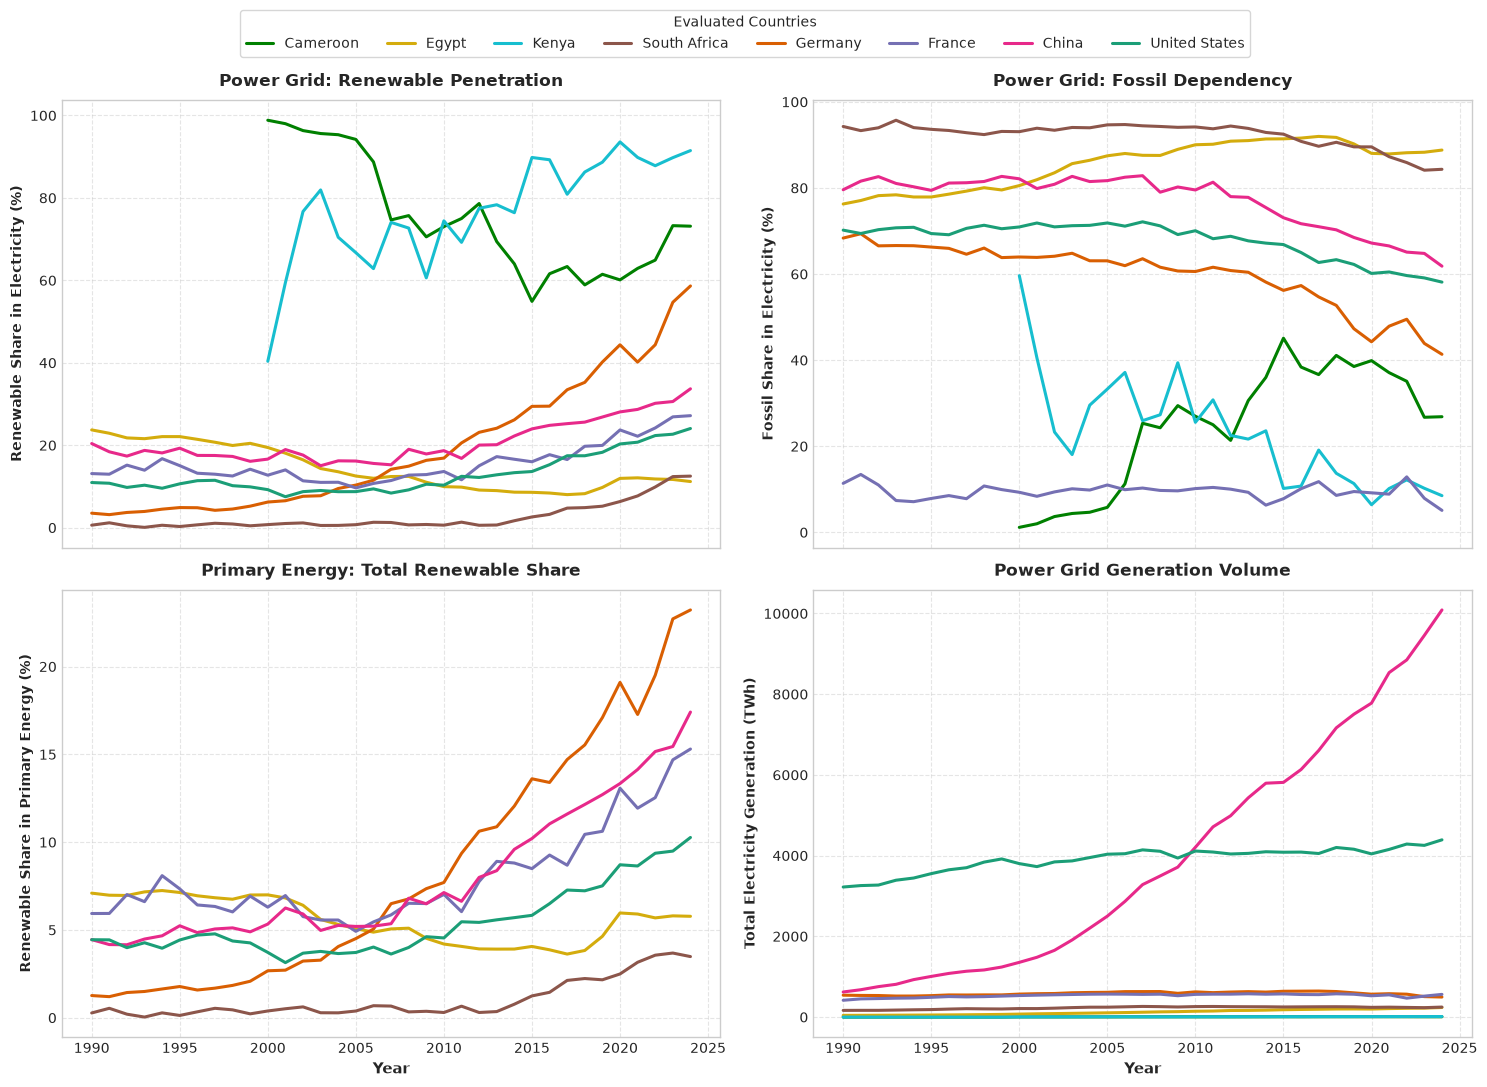

Publication figure saved to: ../figures/global_and_african_power_transition.png


In [8]:
# 6. Visualizing the electricity generation trajectories for selected countries (CMR, EGY, KEN, ZAF, DEU, FRA, CHN)
expanded_cohort = ['CMR', 'EGY', 'KEN', 'ZAF', 'DEU', 'FRA', 'CHN', 'USA']

palette_map = {
    'CMR': '#008000',  # Green (Cameroon)
    'EGY': '#d4ac0d',  # Gold (Egypt)
    'KEN': '#17becf',  # Cyan (Kenya)
    'ZAF': '#8c564b',  # Brown (South Africa)
    'DEU': '#d95f02',  # Orange (Germany)
    'FRA': '#7570b3',  # Purple (France)
    'CHN': '#e7298a',  # Pink (China)
    'USA': '#1b9e77'   # Teal/Green (United States)
}

name_map = {
    'CMR': 'Cameroon',
    'EGY': 'Egypt',
    'KEN': 'Kenya',
    'ZAF': 'South Africa',
    'DEU': 'Germany',
    'FRA': 'France',
    'CHN': 'China',
    'USA': 'United States'
}

fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True)

panels = [
    ('renewables_elec_share_pct', 'Renewable Share in Electricity (%)', axes[0, 0], 'Power Grid: Renewable Penetration'),
    ('fossil_elec_share_pct', 'Fossil Share in Electricity (%)', axes[0, 1], 'Power Grid: Fossil Dependency'),
    ('renewables_share_pct', 'Renewable Share in Primary Energy (%)', axes[1, 0], 'Primary Energy: Total Renewable Share'),
    ('total_elec_accounted_twh', 'Total Electricity Generation (TWh)', axes[1, 1], 'Power Grid Generation Volume')
]

lines_for_legend = []
legend_labels = []

for metric, y_title, ax, panel_title in panels:
    for iso in expanded_cohort:
        sub = analysis_df[analysis_df['iso_code'] == iso]
        # Only plot if entity has valid data for this series
        valid_sub = sub.dropna(subset=[metric])
        if not valid_sub.empty:
            line, = ax.plot(
                valid_sub['year'],
                valid_sub[metric],
                label=name_map[iso],
                color=palette_map[iso],
                linewidth=2.2
            )
            if panel_title == panels[0][3]:
                lines_for_legend.append(line)
                legend_labels.append(name_map[iso])
                
    ax.set_title(panel_title, fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel(y_title, fontsize=10, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

axes[1, 0].set_xlabel('Year', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Year', fontsize=11, fontweight='bold')

# Adding a single legend for all subplots at the top center of the figure
fig.legend(
    lines_for_legend,
    legend_labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.99),
    ncol=8,
    frameon=True,
    fontsize=10,
    title='Evaluated Countries'
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

fig_path = os.path.join('..', 'figures', 'global_and_african_power_transition.png')
plt.savefig(fig_path, dpi=300)
plt.show()

print(f"Publication figure saved to: {fig_path}")

In [9]:
# 1. Identifying per capita and carbon intensity columns
intensity_cols = ['per_capita_electricity', 'carbon_intensity_elec']

# Verifying which intensity columns are available in the dataset
avail_intensity = [col for col in intensity_cols if col in analysis_df.columns]
print(f"Available intensity columns: {avail_intensity}")

# 2. Creating a snapshot of the latest year (2022) for the expanded cohort
latest_year = 2022
snapshot_df = analysis_df[
    (analysis_df['iso_code'].isin(expanded_cohort)) & 
    (analysis_df['year'] == latest_year)
][['year', 'country', 'iso_code', 'per_capita_electricity', 'carbon_intensity_elec', 'renewables_elec_share_pct']].copy()

# 3. Sorting the snapshot DataFrame by carbon intensity for comparative benchmarking
snapshot_sorted = snapshot_df.sort_values(by='carbon_intensity_elec', ascending=True).reset_index(drop=True)

print(f"\nComparative Clean Energy & Grid Intensity Benchmark ({latest_year}):")
display(snapshot_sorted.round(2))

Available intensity columns: ['per_capita_electricity', 'carbon_intensity_elec']

Comparative Clean Energy & Grid Intensity Benchmark (2022):


,year,country,iso_code,per_capita_electricity,carbon_intensity_elec,renewables_elec_share_pct
0,2022,France,FRA,7068.02,78.54,24.20
1,2022,Kenya,KEN,238.88,109.57,87.81
2,2022,Cameroon,CMR,294.94,280.98,64.91
3,2022,United States,USA,12551.87,410.39,22.35
4,2022,Germany,DEU,6741.65,419.74,44.37
5,2022,Egypt,EGY,1924.38,570.04,11.82
6,2022,China,CHN,6208.84,586.75,30.18
7,2022,South Africa,ZAF,3834.18,729.02,9.88


In [ ]:
# Quantifying Carbon Intensity & Per-Capita Access Benchmark (2022)

# 1. Define target analytical columns
intensity_metrics = [
    'per_capita_electricity',     # kWh per person
    'carbon_intensity_elec',      # gCO2 per kWh
    'renewables_elec_share_pct',  # % renewable generation on grid
    'fossil_elec_share_pct'       # % fossil generation on grid
]

# 2. Extracting recent cross-sectional data (2022 / latest reliable reporting year)
latest_year = 2022
snapshot_df = analysis_df[
    (analysis_df['iso_code'].isin(expanded_cohort)) & 
    (analysis_df['year'] == latest_year)
].copy()

# 3. Selecting relevant columns for the snapshot table
display_cols = [
    'country', 
    'iso_code', 
    'per_capita_electricity', 
    'carbon_intensity_elec', 
    'renewables_elec_share_pct',
    'fossil_elec_share_pct'
]

snapshot_table = snapshot_df[display_cols].copy()

# 4. Sorting the snapshot table by carbon intensity for benchmarking
snapshot_table = snapshot_table.sort_values(
    by='carbon_intensity_elec', 
    ascending=True
).reset_index(drop=True)

# Renaming columns for clarity in the final display
snapshot_table.columns = [
    'Country', 
    'ISO', 
    'Per Capita Elec (kWh)', 
    'Carbon Intensity (gCO2/kWh)', 
    'Renewable Share (%)', 
    'Fossil Share (%)'
]

print(f"Grid Decarbonization & Consumption Benchmark ({latest_year}):")
display(snapshot_table.round(2))

Grid Decarbonization & Consumption Benchmark (2022):


,Country,ISO,Per Capita Elec (kWh),Carbon Intensity (gCO2/kWh),Renewable Share (%),Fossil Share (%)
0,France,FRA,7068.02,78.54,24.20,12.88
1,Kenya,KEN,238.88,109.57,87.81,12.19
2,Cameroon,CMR,294.94,280.98,64.91,35.09
3,United States,USA,12551.87,410.39,22.35,59.65
4,Germany,DEU,6741.65,419.74,44.37,49.50
5,Egypt,EGY,1924.38,570.04,11.82,88.18
6,China,CHN,6208.84,586.75,30.18,65.10
7,South Africa,ZAF,3834.18,729.02,9.88,85.90


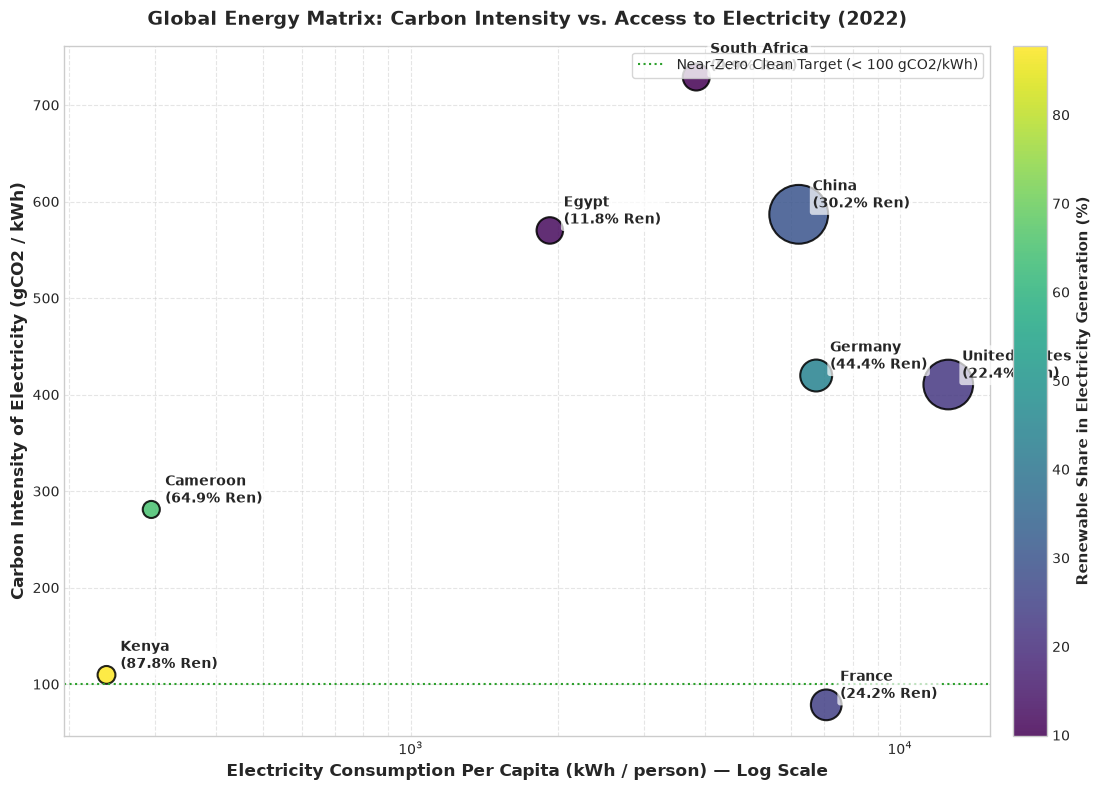

Matrix visualization saved to: ../figures/energy_matrix_intensity_vs_access.png


In [11]:
# Visualizing the Energy Access vs. Decarbonization Matrix (2022)

# Pulling 2022 cross-sectional metrics with total generation volume
matrix_df = analysis_df[
    (analysis_df['iso_code'].isin(expanded_cohort)) & 
    (analysis_df['year'] == 2022)
].copy()

fig, ax = plt.subplots(figsize=(12, 8))

# Scatter plot with bubble sizes proportional to total power generation
# Scaling bubble area for visual balance
sizes = np.sqrt(matrix_df['total_elec_accounted_twh']) * 18 + 100

scatter = ax.scatter(
    matrix_df['per_capita_electricity'],
    matrix_df['carbon_intensity_elec'],
    s=sizes,
    c=matrix_df['renewables_elec_share_pct'],
    cmap='viridis',
    alpha=0.85,
    edgecolors='black',
    linewidth=1.5
)

# Annotating each country with its name and renewable share percentage
for _, row in matrix_df.iterrows():
    ax.annotate(
        f"{row['country']}\n({row['renewables_elec_share_pct']:.1f}% Ren)",
        xy=(row['per_capita_electricity'], row['carbon_intensity_elec']),
        xytext=(10, 5),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none')
    )

# Setting logarithmic scale for the x-axis to better visualize disparities in electricity access
ax.set_xscale('log')
ax.set_xlabel('Electricity Consumption Per Capita (kWh / person) — Log Scale', fontsize=12, fontweight='bold')
ax.set_ylabel('Carbon Intensity of Electricity (gCO2 / kWh)', fontsize=12, fontweight='bold')
ax.set_title('Global Energy Matrix: Carbon Intensity vs. Access to Electricity (2022)', fontsize=14, fontweight='bold', pad=15)

# Adding grid lines for better readability of the scatter plot
ax.grid(True, which='both', linestyle='--', alpha=0.5)

# Adding colorbar indicating renewable penetration
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Renewable Share in Electricity Generation (%)', fontsize=11, fontweight='bold')

# Adding reference threshold line
ax.axhline(100, color='#2ca02c', linestyle=':', linewidth=1.5, label='Near-Zero Clean Target (< 100 gCO2/kWh)')
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()

# Saving the matrix visualization to the 'figures' directory with high resolution
output_fig_path = os.path.join('..', 'figures', 'energy_matrix_intensity_vs_access.png')
plt.savefig(output_fig_path, dpi=300)
plt.show()

print(f"Matrix visualization saved to: {output_fig_path}")

In [12]:
# Multi-Year Growth Dynamics and Access Correlation (2000 to 2022)

# Filter cohort data for the 2000-2022 period
growth_cohort = analysis_df[
    (analysis_df['iso_code'].isin(expanded_cohort)) & 
    (analysis_df['year'].isin([2000, 2022]))
].copy()

# Creating pivot tables for electricity generation, renewables, per-capita consumption, and population for the years 2000 and 2022
pivot_gen = growth_cohort.pivot(index='country', columns='year', values='total_elec_accounted_twh')
pivot_ren = growth_cohort.pivot(index='country', columns='year', values='renewables_electricity')
pivot_cap = growth_cohort.pivot(index='country', columns='year', values='per_capita_electricity')
pivot_pop = growth_cohort.pivot(index='country', columns='year', values='population')

# Calculating the number of years between 2000 and 2022 for growth rate calculations
n_years = 2022 - 2000

# 2. Build summary growth DataFrame
growth_summary = pd.DataFrame(index=pivot_gen.index)
growth_summary['ISO'] = [growth_cohort[growth_cohort['country'] == c]['iso_code'].iloc[0] for c in growth_summary.index]

# Calculating total electricity generation growth
growth_summary['Total Elec 2000 (TWh)'] = pivot_gen[2000]
growth_summary['Total Elec 2022 (TWh)'] = pivot_gen[2022]
growth_summary['Total Elec Growth (%)'] = ((pivot_gen[2022] - pivot_gen[2000]) / pivot_gen[2000]) * 100

# Calculating renewable generation additions
growth_summary['Renewables 2000 (TWh)'] = pivot_ren[2000]
growth_summary['Renewables 2022 (TWh)'] = pivot_ren[2022]
growth_summary['Renewable Addition (TWh)'] = pivot_ren[2022] - pivot_ren[2000]

# Calculating per capita electricity growth and population growth
growth_summary['Per Capita 2000 (kWh)'] = pivot_cap[2000]
growth_summary['Per Capita 2022 (kWh)'] = pivot_cap[2022]
growth_summary['Per Capita Growth (%)'] = ((pivot_cap[2022] - pivot_cap[2000]) / pivot_cap[2000]) * 100
growth_summary['Population Growth (%)'] = ((pivot_pop[2022] - pivot_pop[2000]) / pivot_pop[2000]) * 100

# Sorting the growth summary DataFrame by total electricity growth percentage in descending order for better comparative analysis
growth_summary = growth_summary.sort_values(by='Total Elec Growth (%)', ascending=False)

# Selecting columns for display
display_cols = [
    'ISO', 
    'Total Elec Growth (%)', 
    'Renewable Addition (TWh)', 
    'Population Growth (%)', 
    'Per Capita Growth (%)'
]

print("Structural Growth & Electrification Dynamics (2000 - 2022):")
display(growth_summary[display_cols].round(2))

Structural Growth & Electrification Dynamics (2000 - 2022):


,ISO,Total Elec Growth (%),Renewable Addition (TWh),Population Growth (%),Per Capita Growth (%)
country,,,,,
China,CHN,552.75,2445.10,12.26,481.49
Kenya,KEN,200.70,9.64,77.05,69.84
Egypt,EGY,195.58,11.35,54.10,91.82
Cameroon,CMR,136.23,1.88,85.30,27.49
South Africa,ZAF,13.53,22.04,32.27,-14.17
United States,USA,12.75,607.21,21.33,-7.07
Germany,DEU,-0.36,216.13,2.80,-3.08
France,FRA,-12.04,45.54,11.42,-21.05


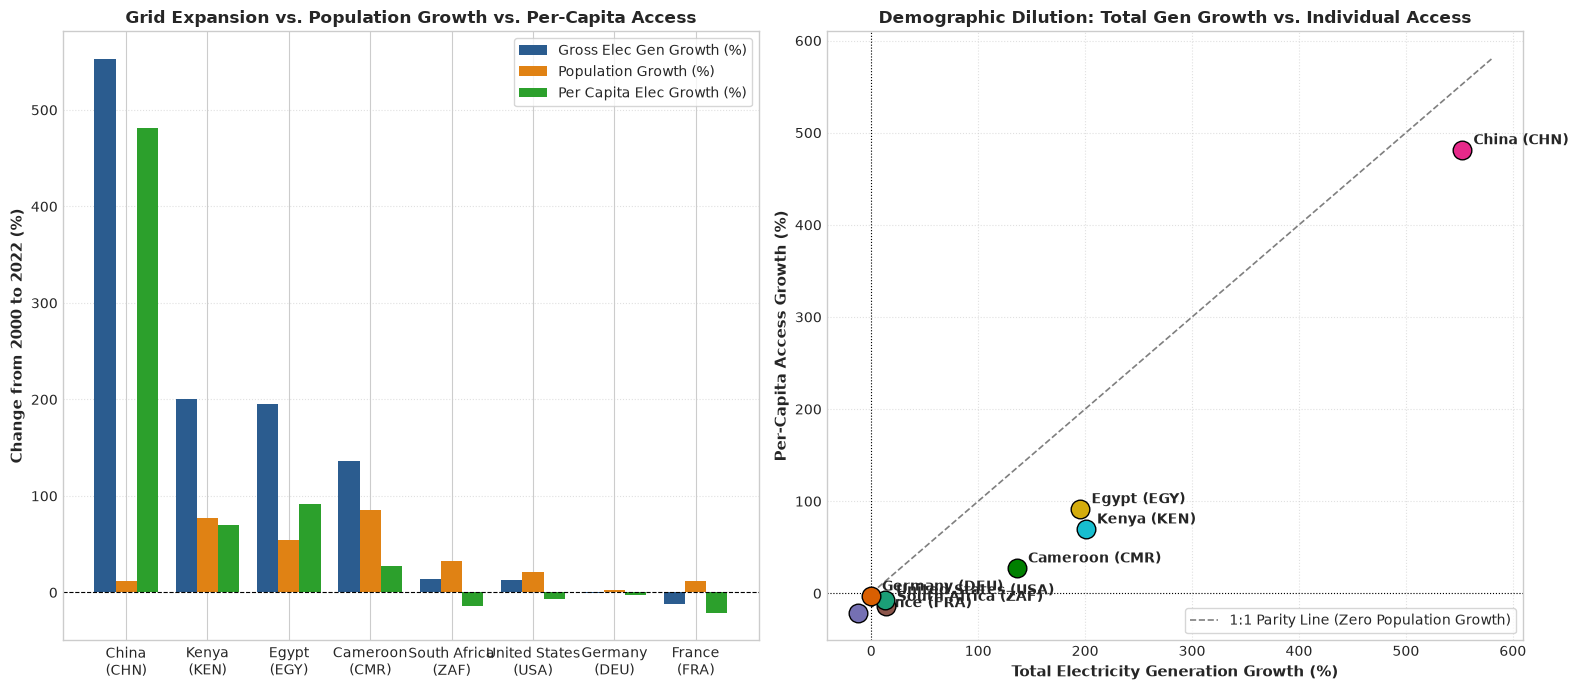

Growth visualization saved to: ../figures/access_growth_dilution_analysis.png


In [13]:
# Setting up a 1x2 grid of subplots for growth comparisons and access dilution analysis

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

#  Panel A: Grouped Growth Comparisons 
countries = growth_summary.index.tolist()
x = np.arange(len(countries))
width = 0.26

rects1 = axes[0].bar(x - width, growth_summary['Total Elec Growth (%)'], width, label='Gross Elec Gen Growth (%)', color='#2b5c8f')
rects2 = axes[0].bar(x, growth_summary['Population Growth (%)'], width, label='Population Growth (%)', color='#e08214')
rects3 = axes[0].bar(x + width, growth_summary['Per Capita Growth (%)'], width, label='Per Capita Elec Growth (%)', color='#2ca02c')

axes[0].set_ylabel('Change from 2000 to 2022 (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Grid Expansion vs. Population Growth vs. Per-Capita Access', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{c}\n({growth_summary.loc[c, 'ISO']})" for c in countries], fontsize=10)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].grid(True, linestyle=':', alpha=0.6, axis='y')
axes[0].legend(frameon=True, fontsize=10)

#  Panel B: Access Dilution Scatter & Elasticity
for c in countries:
    iso = growth_summary.loc[c, 'ISO']
    axes[1].scatter(
        growth_summary.loc[c, 'Total Elec Growth (%)'],
        growth_summary.loc[c, 'Per Capita Growth (%)'],
        s=180,
        color=palette_map.get(iso, '#333333'),
        edgecolors='black',
        zorder=4
    )
    # Positioning annotations
    axes[1].annotate(
        f"{c} ({iso})",
        xy=(growth_summary.loc[c, 'Total Elec Growth (%)'], growth_summary.loc[c, 'Per Capita Growth (%)']),
        xytext=(8, 4),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold'
    )

# Adding a 1:1 parity line to indicate zero population growth scenario
line_max = 580
axes[1].plot([0, line_max], [0, line_max], color='#7f7f7f', linestyle='--', linewidth=1.2, label='1:1 Parity Line (Zero Population Growth)')

axes[1].set_xlabel('Total Electricity Generation Growth (%)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Per-Capita Access Growth (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Demographic Dilution: Total Gen Growth vs. Individual Access', fontsize=12, fontweight='bold')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle=':')
axes[1].axvline(0, color='black', linewidth=0.8, linestyle=':')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()

# Save figure
growth_fig_path = os.path.join('..', 'figures', 'access_growth_dilution_analysis.png')
plt.savefig(growth_fig_path, dpi=300)
plt.show()

print(f"Growth visualization saved to: {growth_fig_path}")

In [14]:
# Does adding renewables correlate with increased access to electricity across developing vs. developed grids? (Renewable Additions vs. Access)

# Computing Renewable Generation Growth (%) from 2000 to 2022
growth_summary['Renewable Growth (%)'] = np.where(
    growth_summary['Renewables 2000 (TWh)'] > 0,
    ((growth_summary['Renewables 2022 (TWh)'] - growth_summary['Renewables 2000 (TWh)']) / growth_summary['Renewables 2000 (TWh)']) * 100,
    np.nan
)

# Computing Access Elasticity to Renewables
# Measures % gain in per-capita access per 1% growth in renewable power
growth_summary['Access Elasticity (eps)'] = (
    growth_summary['Per Capita Growth (%)'] / growth_summary['Renewable Growth (%)']
)

# Classifying countries into transition regimes based on per-capita growth and access elasticity
def classify_regime(row):
    if row['Per Capita Growth (%)'] < 0:
        return 'Substitution / Decoupling'
    elif row['Access Elasticity (eps)'] >= 0.5:
        return 'High Expansion Leverage'
    else:
        return 'Demographically Diluted Expansion'

growth_summary['Transition Regime'] = growth_summary.apply(classify_regime, axis=1)

# Displaying the elasticity and structural transition regimes in a sorted table
elasticity_table = growth_summary[[
    'ISO',
    'Renewable Addition (TWh)',
    'Renewable Growth (%)',
    'Per Capita Growth (%)',
    'Access Elasticity (eps)',
    'Transition Regime'
]].sort_values(by='Per Capita Growth (%)', ascending=False)

print("Elasticity & Structural Transition Regimes (2000 - 2022):")
display(elasticity_table.round(3))

# Correlation Matrix across growth metrics
corr_matrix = growth_summary[[
    'Total Elec Growth (%)',
    'Renewable Growth (%)',
    'Renewable Addition (TWh)',
    'Population Growth (%)',
    'Per Capita Growth (%)'
]].corr(method='spearman')

print("\nSpearman Rank Correlation Matrix:")
display(corr_matrix.round(2))

Elasticity & Structural Transition Regimes (2000 - 2022):


,ISO,Renewable Addition (TWh),Renewable Growth (%),Per Capita Growth (%),Access Elasticity (eps),Transition Regime
country,,,,,,
China,CHN,2445.10,1084.013,481.486,0.444,Demographically Diluted Expansion
Egypt,EGY,11.35,79.593,91.816,1.154,High Expansion Leverage
Kenya,KEN,9.64,554.023,69.839,0.126,Demographically Diluted Expansion
Cameroon,CMR,1.88,55.132,27.488,0.499,Demographically Diluted Expansion
Germany,DEU,216.13,610.364,-3.076,-0.005,Substitution / Decoupling
United States,USA,607.21,173.029,-7.074,-0.041,Substitution / Decoupling
South Africa,ZAF,22.04,1394.937,-14.166,-0.010,Substitution / Decoupling
France,FRA,45.54,67.138,-21.055,-0.314,Substitution / Decoupling



Spearman Rank Correlation Matrix:


,Total Elec Growth (%),Renewable Growth (%),Renewable Addition (TWh),Population Growth (%),Per Capita Growth (%)
Total Elec Growth (%),1.00,0.24,-0.17,0.55,0.88
Renewable Growth (%),0.24,1.00,0.48,-0.33,0.10
Renewable Addition (TWh),-0.17,0.48,1.00,-0.81,-0.05
Population Growth (%),0.55,-0.33,-0.81,1.00,0.33
Per Capita Growth (%),0.88,0.10,-0.05,0.33,1.00


In [15]:
# Saving the processed benchmark and growth elasticity datasets to CSV files for future reference
processed_benchmark_path = os.path.join('..', 'data', 'processed_transition_benchmark_2022.csv')
snapshot_table.to_csv(processed_benchmark_path, index=False)

processed_growth_path = os.path.join('..', 'data', 'processed_growth_elasticity_2000_2022.csv')
growth_summary.to_csv(processed_growth_path, index=True)

print(f"Benchmark dataset saved: {processed_benchmark_path}")
print(f"Growth elasticity dataset saved: {processed_growth_path}")

Benchmark dataset saved: ../data/processed_transition_benchmark_2022.csv
Growth elasticity dataset saved: ../data/processed_growth_elasticity_2000_2022.csv
